# Context length experiments

In [1]:
# Imports and setup

import torch
from matplotlib import pyplot as plt
import os
import numpy as np

from experiments_helper import (
    run_experiment_suite,
    compute_loss_dict,
    compute_dist_dict,
    plot_loss_curves,
    plot_parameter_matrices,
    plot_dist_to_identity,
)

np.set_printoptions(precision=2, suppress=True)
torch.set_printoptions(precision=2)

log_dir = 'log'
cur_dir = log_dir
os.makedirs(cur_dir, exist_ok=True)

In [2]:
# Problem parameters (defined in experiments_helper.py; edit them there so the
# helper functions see the same values)

from experiments_helper import (
    device, lr, clip_r, alg, normal_data_mode, N, d, n_head, B, var,
    max_iters, hist_stride, stride, TEST_SEED,
)

print(f'Running on device: {device}.')

Running on device: cuda.


In [3]:
# Training-iteration grid shared with the regular experiments.
iterations = np.arange(0, max_iters, stride)

In [ ]:
# Figure 1 computations: looped transformers across context lengths.
f1_seeds = [0, 1]
fig2_N_values = [3, 6, 10, 20, 50]
f1_loop_counts = [5]
f1_model_types = ['looped']
f1_filename = cur_dir + '/figure_one_looped_{}.pth'.format(d)
f1_fig_dir = os.path.join('figures', 'figure_one')
os.makedirs(f1_fig_dir, exist_ok=True)

f1_hist = run_experiment_suite(
    f1_seeds, f1_loop_counts, f1_model_types, f1_filename, context_lengths=fig2_N_values)
f1_loss = compute_loss_dict(f1_hist, test_seed=TEST_SEED)
f1_dist = compute_dist_dict(f1_hist, iterations, n_head, hist_stride=hist_stride)


Run 1/2: seed=0, count=5, type=looped, N=3, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear
iter 0 | Loss: 7.9477033615112305 | time: 0.29605889320373535 | gradnorm: 24.05768585205078
iter 1 | Loss: 7.842301368713379 | time: 0.008618593215942383 | gradnorm: 24.352602005004883
iter 2 | Loss: 7.708634376525879 | time: 0.007351398468017578 | gradnorm: 22.253528594970703
iter 3 | Loss: 7.621252059936523 | time: 0.007510662078857422 | gradnorm: 24.045963287353516
iter 4 | Loss: 7.326205253601074 | time: 0.007247447967529297 | gradnorm: 21.654386520385742
iter 100 | Loss: 4.014070510864258 | time: 0.012109994888305664 | gradnorm: 13.752267837524414
iter 200 | Loss: 2.9106285572052 | time: 0.014419078826904297 | gradnorm: 4.585430145263672
iter 300 | Loss: 2.688432455062866 | time: 0.012194395065307617 | gradnorm: 1.5489490032196045
iter 400 | Loss: 2.3576500415802 | time: 0.013923406600952148 | gradnorm: 0.8703522086143494
i

TypeError: int() argument must be a string, a bytes-like object or a real number, not 'NoneType'

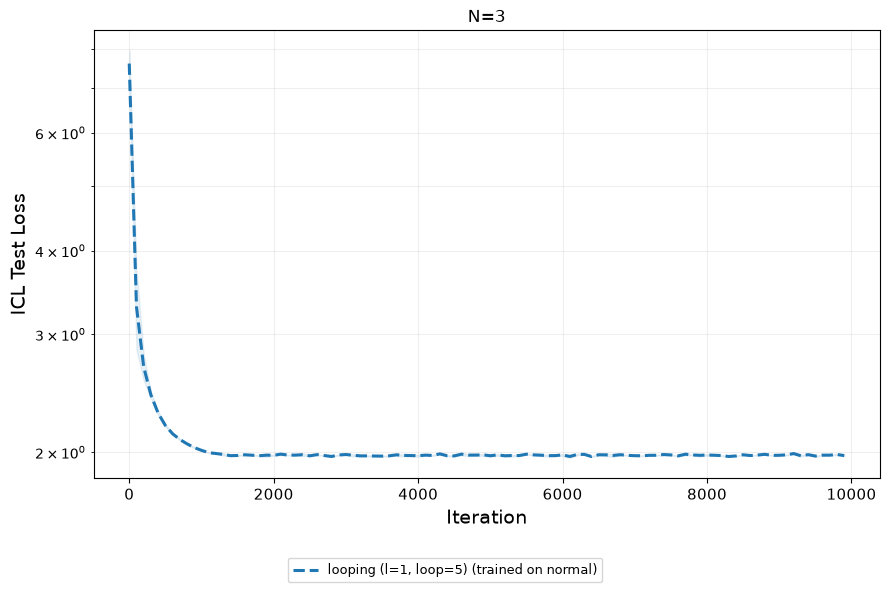

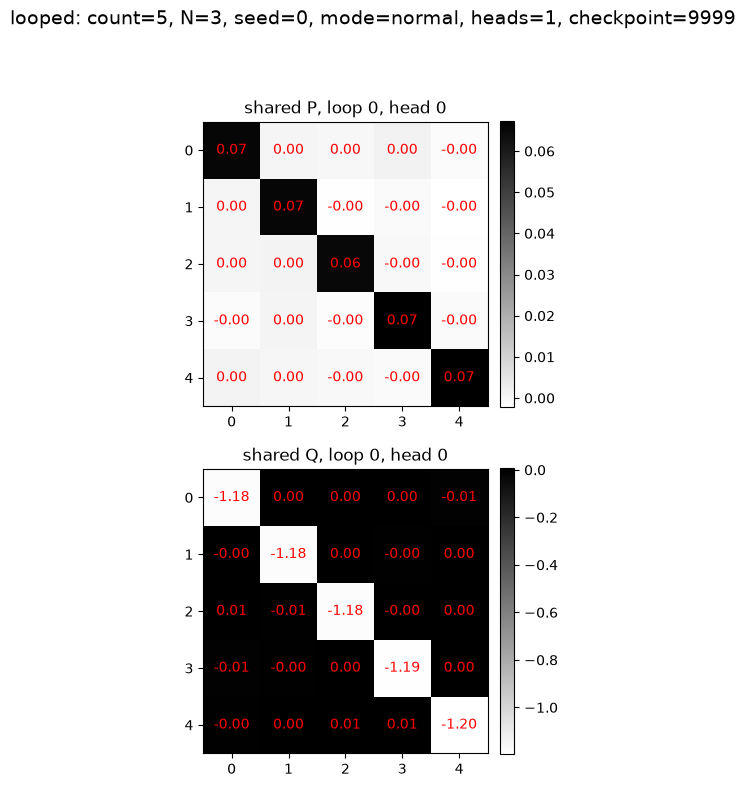

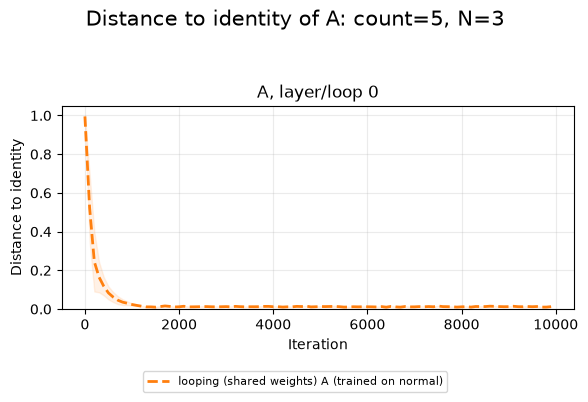

In [6]:
# Figure 1 plots, immediately following the computation cell.
plot_loss_curves(
    f1_loss,
    f1_loop_counts,
    f1_model_types,
    iterations,
    fig_dir=f1_fig_dir,
    filename='figure_one_test_loss.pdf',
)
plot_parameter_matrices(
    f1_hist,
    f1_seeds[0],
    f1_loop_counts,
    f1_model_types,
    n_head,
    hist_stride=hist_stride,
    fig_dir=f1_fig_dir,
)
plot_dist_to_identity(
    f1_dist,
    f1_loop_counts,
    iterations,
    fig_dir=f1_fig_dir,
)